# Proyecto EDA: Análisis exploratorio de datos COVID-19 en Estados Unidos

## 1. Introducción

El objetivo de este proyecto es realizar un análisis exploratorio de datos (EDA) sobre la evolución de la pandemia de COVID-19 en Estados Unidos.

A través de Python y sus principales librerías de análisis de datos, se estudiará la evolución de los casos confirmados, las pruebas realizadas y los fallecimientos registrados en los diferentes estados.

El análisis permitirá identificar tendencias temporales, diferencias entre estados y posibles patrones relacionados con el impacto de la pandemia.

El proyecto se desarrolla hasta el **Nivel Medio**: además del análisis esencial, se justifican las decisiones de limpieza, se detectan valores atípicos, se agrupan y resumen los datos con `groupby`/`agg` y `pivot_table`, se crean variables nuevas, se calcula una matriz de correlación y se analizan tendencias temporales con medias móviles.

## 2. Objetivos

- Analizar la estructura y calidad del conjunto de datos.
- Identificar y tratar valores faltantes, duplicados e inconsistencias.
- Estudiar la evolución temporal de los principales indicadores.
- Comparar el impacto de la pandemia entre estados.
- Detectar valores atípicos y justificar qué hacer con ellos.
- Agrupar y resumir la información por estado y por mes.
- Crear variables nuevas y analizar correlaciones.
- Crear visualizaciones que faciliten la interpretación de los resultados.
- Comunicar los principales hallazgos.

### 2.1. Preguntas de investigación

Antes de analizar los datos nos planteamos estas tres preguntas:

1. **Evolución temporal:** ¿cómo evolucionaron los casos nuevos y los fallecimientos durante el periodo?
2. **Comparación entre estados:** ¿qué estados concentraron más casos positivos?
3. **Relación pruebas–casos:** ¿existe relación entre el número de pruebas realizadas y los casos positivos?

Estas preguntas se responden en la sección 8.


## 2. Cargar los datos

En esta sección descargamos el dataset desde la API pública del *COVID Tracking Project* y lo dejamos preparado para el análisis.

### 2.1. Importar librerías

Primero, importamos las librerías necesarias para la descarga, manipulación y visualización de los datos.

In [1]:
from pathlib import Path

import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option(
    "display.float_format",
    lambda x: f"{x:,.2f}" if x % 1 else f"{x:,.0f}",
)

### 2.2. Descargar o leer el dataset

Para no descargar los datos en cada ejecución, el notebook lee el CSV local si ya existe. Si no existe, descarga los datos desde la API y los guarda en `data/covid_us.csv`.

In [2]:
URL = "https://api.covidtracking.com/v1/states/daily.json"
DATA_PATH = Path("../data/covid_us.csv")

if DATA_PATH.exists():
    df = pd.read_csv(DATA_PATH)
    print(f"Datos cargados desde {DATA_PATH}")
else:
    response = requests.get(URL, timeout=30)
    response.raise_for_status()
    df = pd.DataFrame(response.json())
    DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(DATA_PATH, index=False)
    print("Datos descargados desde la API")

df.head()

Datos cargados desde ../data/covid_us.csv


,date,state,positive,probableCases,negative,pending,totalTestResultsSource,totalTestResults,hospitalizedCurrently,hospitalizedCumulative,...,dataQualityGrade,deathIncrease,hospitalizedIncrease,hash,commercialScore,negativeRegularScore,negativeScore,positiveScore,score,grade
0,20210307,AK,"56,886",NaN,NaN,NaN,totalTestsViral,"1,731,628",33,"1,293",...,NaN,0,0,dc4bccd4bb885349d7e94d6fed058e285d4be164,0,0,0,0,0,NaN
1,20210307,AL,"499,819","107,742","1,931,711",NaN,totalTestsPeopleViral,"2,323,788",494,"45,976",...,NaN,-1,0,997207b430824ea40b8eb8506c19a93e07bc972e,0,0,0,0,0,NaN
2,20210307,AR,"324,818","69,092","2,480,716",NaN,totalTestsViral,"2,736,442",335,"14,926",...,NaN,22,11,50921aeefba3e30d31623aa495b47fb2ecc72fae,0,0,0,0,0,NaN
3,20210307,AS,0,NaN,"2,140",NaN,totalTestsViral,"2,140",NaN,NaN,...,NaN,0,0,f77912d0b80d579fbb6202fa1a90554fc4dc1443,0,0,0,0,0,NaN
4,20210307,AZ,"826,454","56,519","3,073,010",NaN,totalTestsViral,"7,908,105",963,"57,907",...,NaN,5,44,0437a7a96f4471666f775e63e86923eb5cbd8cdf,0,0,0,0,0,NaN


## 3. Revisión de la estructura del dataset

Antes de limpiar los datos, revisamos su tamaño, los tipos de cada columna y las primeras filas para entender qué información contienen.

In [3]:
# Número de filas y columnas
df.shape

(20780, 56)

In [4]:
# Información general
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20780 entries, 0 to 20779
Data columns (total 56 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   date                         20780 non-null  int64  
 1   state                        20780 non-null  str    
 2   positive                     20592 non-null  float64
 3   probableCases                9271 non-null   float64
 4   negative                     13290 non-null  float64
 5   pending                      2138 non-null   float64
 6   totalTestResultsSource       20780 non-null  str    
 7   totalTestResults             20614 non-null  float64
 8   hospitalizedCurrently        17339 non-null  float64
 9   hospitalizedCumulative       12382 non-null  float64
 10  inIcuCurrently               11636 non-null  float64
 11  inIcuCumulative              3789 non-null   float64
 12  onVentilatorCurrently        9126 non-null   float64
 13  onVentilatorCumulative     

In [5]:
# Primeras filas
df.head()

,date,state,positive,probableCases,negative,pending,totalTestResultsSource,totalTestResults,hospitalizedCurrently,hospitalizedCumulative,...,dataQualityGrade,deathIncrease,hospitalizedIncrease,hash,commercialScore,negativeRegularScore,negativeScore,positiveScore,score,grade
0,20210307,AK,"56,886",NaN,NaN,NaN,totalTestsViral,"1,731,628",33,"1,293",...,NaN,0,0,dc4bccd4bb885349d7e94d6fed058e285d4be164,0,0,0,0,0,NaN
1,20210307,AL,"499,819","107,742","1,931,711",NaN,totalTestsPeopleViral,"2,323,788",494,"45,976",...,NaN,-1,0,997207b430824ea40b8eb8506c19a93e07bc972e,0,0,0,0,0,NaN
2,20210307,AR,"324,818","69,092","2,480,716",NaN,totalTestsViral,"2,736,442",335,"14,926",...,NaN,22,11,50921aeefba3e30d31623aa495b47fb2ecc72fae,0,0,0,0,0,NaN
3,20210307,AS,0,NaN,"2,140",NaN,totalTestsViral,"2,140",NaN,NaN,...,NaN,0,0,f77912d0b80d579fbb6202fa1a90554fc4dc1443,0,0,0,0,0,NaN
4,20210307,AZ,"826,454","56,519","3,073,010",NaN,totalTestsViral,"7,908,105",963,"57,907",...,NaN,5,44,0437a7a96f4471666f775e63e86923eb5cbd8cdf,0,0,0,0,0,NaN


In [6]:
# Estadísticas descriptivas
df.describe()

,date,positive,probableCases,negative,pending,totalTestResults,hospitalizedCurrently,hospitalizedCumulative,inIcuCurrently,inIcuCumulative,...,posNeg,dataQualityGrade,deathIncrease,hospitalizedIncrease,commercialScore,negativeRegularScore,negativeScore,positiveScore,score,grade
count,"20,780","20,592","9,271","13,290","2,138","20,614","17,339","12,382","11,636","3,789",...,"20,780",0,"20,780","20,780","20,780","20,780","20,780","20,780","20,780",0
mean,"20,202,440.02","165,155.97","21,729.12","848,224.62","1,659.86","2,186,935.75","1,190.58","9,262.76",359.62,"1,934.19",...,"706,150.00",NaN,24.79,37.36,0,0,0,0,0,NaN
std,"3,608.73","326,785.24","45,471.46","1,344,501.36","4,671.03","4,436,508.15","2,060.04","12,620.54",594.83,"1,953.33",...,"1,299,996.54",NaN,60.16,208.24,0,0,0,0,0,NaN
min,"20,200,113",0,0,0,0,0,0,1,0,6,...,0,NaN,-201,"-12,257",0,0,0,0,0,NaN
25%,"20,200,602","5,753.75",773.50,"53,941.25",43,"104,049.75",166.50,985.25,60,501,...,"25,658.75",NaN,0,0,0,0,0,0,0,NaN
50%,"20,200,903","46,064.50","4,491","305,972",212.50,"655,267",531,"4,472",172,"1,295",...,"193,581",NaN,6,0,0,0,0,0,0,NaN
75%,"20,201,205","177,958","19,553","1,056,611.25","1,295.75","2,264,766.50","1,279","12,248.50",380,"2,451",...,"773,740.75",NaN,24,36,0,0,0,0,0,NaN
max,"20,210,307","3,501,394","365,961","10,186,941","64,400","49,646,014","22,851","82,237","5,225","9,263",...,"11,248,247",NaN,"2,559","16,373",0,0,0,0,0,NaN


El dataset contiene **20.780 registros y 56 columnas**: un registro por estado o territorio y día, entre el **13 de enero de 2020** y el **7 de marzo de 2021** (56 estados/territorios en total).

`info()` muestra que la mayoría de las columnas son numéricas, pero `date` viene como entero (`20210307`) y hay muchas columnas con gran cantidad de valores nulos. `describe()` confirma que las medidas acumuladas están muy sesgadas: la media de casos positivos es mucho mayor que la mediana, porque unos pocos estados grandes concentran gran parte de los casos.

## 4. Limpieza de datos

En esta sección identificamos duplicados y valores faltantes, corregimos los tipos de datos y seleccionamos las columnas que utilizaremos en el análisis. Cada decisión se justifica en el texto.

### 4.1. Duplicados

Comprobamos si hay filas repetidas y si se repite la combinación de estado y fecha, que debería ser única.

In [7]:
print("Filas duplicadas:", df.duplicated().sum())
print("Duplicados por estado y fecha:", df.duplicated(subset=["state", "date"]).sum())

Filas duplicadas: 0
Duplicados por estado y fecha: 0


No hay filas duplicadas ni duplicados de `(estado, fecha)`. Por tanto, cada observación es única y no es necesario eliminar registros.

### 4.2. Valores faltantes

Calculamos el número y el porcentaje de nulos por columna.

In [8]:
nulos = df.isna().sum()
resumen_nulos = pd.DataFrame({
    "nulos": nulos,
    "porcentaje": (nulos / len(df) * 100).round(1),
}).sort_values("porcentaje", ascending=False)

resumen_nulos.head(15)

,nulos,porcentaje
grade,20780,100
dataQualityGrade,20780,100
positiveTestsPeopleAntigen,20147,97
negativeTestsPeopleAntibody,19808,95.30
totalTestsPeopleAntigen,19781,95.20
positiveTestsPeopleAntibody,19686,94.70
onVentilatorCumulative,19490,93.80
negativeTestsAntibody,19322,93
pending,18642,89.70
totalTestsPeopleAntibody,18580,89.40


La tabla muestra que **14 columnas superan el 80 % de nulos** (por ejemplo `pending`, `inIcuCumulative`, `onVentilatorCumulative`, `hospitalizedDischarged` y las de anticuerpos y antígenos). Además, `dataQualityGrade` y `grade` están **vacías al 100 %**.

Imputar columnas con tan poca información añadiría ruido sin aportar valor. Por eso decidimos **seleccionar un subconjunto de variables relevantes** y descartar el resto.

### 4.3. Selección y renombrado de columnas

Nos quedamos con 10 columnas relacionadas con las preguntas de investigación: fecha, estado, casos, pruebas, fallecimientos y hospitalizaciones. Las renombramos al español para que el notebook sea más legible.

In [9]:
columnas = {
    "date": "fecha",
    "state": "estado",
    "positive": "casos_positivos",
    "negative": "pruebas_negativas",
    "death": "fallecimientos",
    "totalTestResults": "pruebas_totales",
    "hospitalizedCurrently": "hospitalizados_actuales",
    "positiveIncrease": "casos_nuevos",
    "deathIncrease": "fallecimientos_nuevos",
    "totalTestResultsIncrease": "pruebas_nuevas",
}

df = df[list(columnas)].rename(columns=columnas)
df.head()

,fecha,estado,casos_positivos,pruebas_negativas,fallecimientos,pruebas_totales,hospitalizados_actuales,casos_nuevos,fallecimientos_nuevos,pruebas_nuevas
0,20210307,AK,"56,886",NaN,305,"1,731,628",33,0,0,0
1,20210307,AL,"499,819","1,931,711","10,148","2,323,788",494,408,-1,2347
2,20210307,AR,"324,818","2,480,716","5,319","2,736,442",335,165,22,3380
3,20210307,AS,0,"2,140",0,"2,140",NaN,0,0,0
4,20210307,AZ,"826,454","3,073,010","16,328","7,908,105",963,1335,5,45110


Eliminamos 46 columnas: metadatos que no aportan al análisis (`hash`, `fips`), puntuaciones internas del proyecto (`score`, `grade`, `commercialScore`, etc.) y variables con más del 74 % de nulos. Conservar solo las variables relevantes hace que el análisis sea más claro y reproducible.

### 4.4. Corrección de tipos de datos

`fecha` está almacenada como un entero con formato `AAAAMMDD`; la convertimos a fecha real. También convertimos `estado` a variable categórica, porque tiene un número limitado de valores repetidos.

In [10]:
df["fecha"] = pd.to_datetime(df["fecha"].astype(str), format="%Y%m%d")
df["estado"] = df["estado"].astype("category")

# Ordenamos por estado y fecha para poder rellenar series temporales
df = df.sort_values(["estado", "fecha"]).reset_index(drop=True)

df.dtypes

fecha                      datetime64[us]
estado                           category
casos_positivos                   float64
pruebas_negativas                 float64
fallecimientos                    float64
pruebas_totales                   float64
hospitalizados_actuales           float64
casos_nuevos                        int64
fallecimientos_nuevos               int64
pruebas_nuevas                      int64
dtype: object

### 4.5. Tratamiento de los valores faltantes

Las columnas acumuladas (`casos_positivos`, `pruebas_negativas`, `fallecimientos` y `pruebas_totales`) son series temporales por estado. Rellenamos sus nulos con el último valor conocido del mismo estado (`ffill`), ya que un acumulado no puede disminuir y el dato anterior es la mejor aproximación disponible.

`hospitalizados_actuales` es una medida instantánea, no un acumulado; por eso **no la imputamos** y mantenemos sus nulos.

In [11]:
columnas_acumuladas = [
    "casos_positivos",
    "pruebas_negativas",
    "fallecimientos",
    "pruebas_totales",
]

df[columnas_acumuladas] = (
    df.groupby("estado", observed=True)[columnas_acumuladas].ffill()
)

In [12]:
df[
    [
        "casos_positivos",
        "pruebas_negativas",
        "fallecimientos",
        "pruebas_totales",
        "hospitalizados_actuales",
    ]
].isna().sum()

casos_positivos             188
pruebas_negativas          6234
fallecimientos              850
pruebas_totales             166
hospitalizados_actuales    3441
dtype: int64

Tras el relleno, los nulos restantes en las columnas acumuladas están al principio de la serie de cada estado (antes de su primer dato reportado), por lo que no hay un valor anterior que utilizar. No los eliminamos para no perder registros; las visualizaciones descartan esos valores de forma automática.

### 4.6. Inconsistencias: incrementos negativos

Algunos estados notificaron incrementos diarios negativos. No son errores del análisis: son **correcciones retroactivas** que hicieron los estados sobre sus acumulados. Las documentamos y las mantenemos, ya que eliminarlas alteraría la serie original.

In [13]:
for col in ["casos_nuevos", "fallecimientos_nuevos", "pruebas_nuevas"]:
    print(f"{col}: {(df[col] < 0).sum()} valores negativos")

casos_nuevos: 24 valores negativos
fallecimientos_nuevos: 73 valores negativos
pruebas_nuevas: 49 valores negativos


### 4.7. Guardar el dataset limpio

Guardamos una copia del dataset limpio para poder reutilizarlo. Este archivo también está excluido del control de versiones.

In [14]:
df.to_csv("../data/covid_us_clean.csv", index=False)
print(f"Dataset limpio: {df.shape[0]:,} filas x {df.shape[1]} columnas")

Dataset limpio: 20,780 filas x 10 columnas


## 5. Análisis univariado

Analizamos tres variables por separado: los casos positivos acumulados, la cobertura de registros por estado y los fallecimientos acumulados.

### 5.1. Distribución de los casos positivos acumulados

Como los acumulados abarcan varios órdenes de magnitud, usamos una escala logarítmica en el eje X para que la forma de la distribución sea visible.

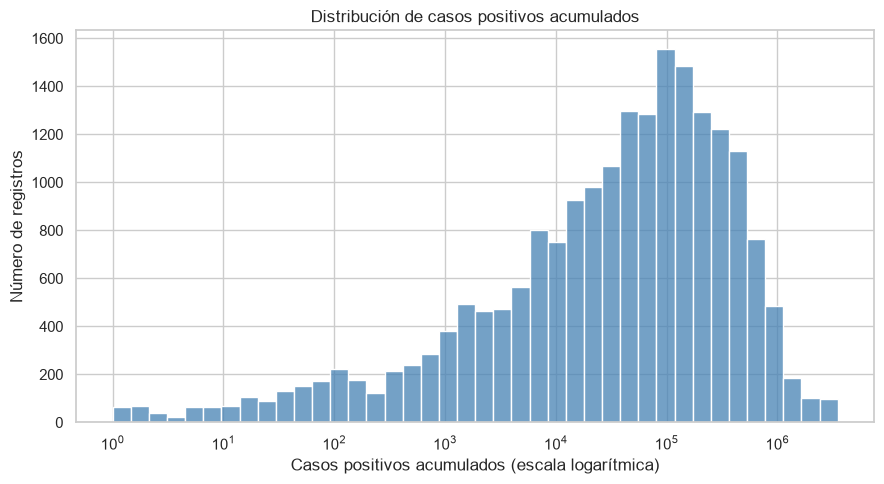

In [15]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(
    df["casos_positivos"].dropna(),
    bins=40,
    log_scale=True,
    color="steelblue",
    ax=ax,
)
ax.set_title("Distribución de casos positivos acumulados")
ax.set_xlabel("Casos positivos acumulados (escala logarítmica)")
ax.set_ylabel("Número de registros")
plt.tight_layout()
plt.show()

La distribución es **asimétrica a la derecha**: la mayoría de los registros se concentran en valores bajos y una cola larga recoge los estados con más casos. Esto confirma que comparar totales sin normalizar favorece a los estados más grandes.

### 5.2. Número de registros por estado

Comprobamos cuántos días aporta cada estado. Una cobertura desigual podría sesgar las comparaciones temporales.

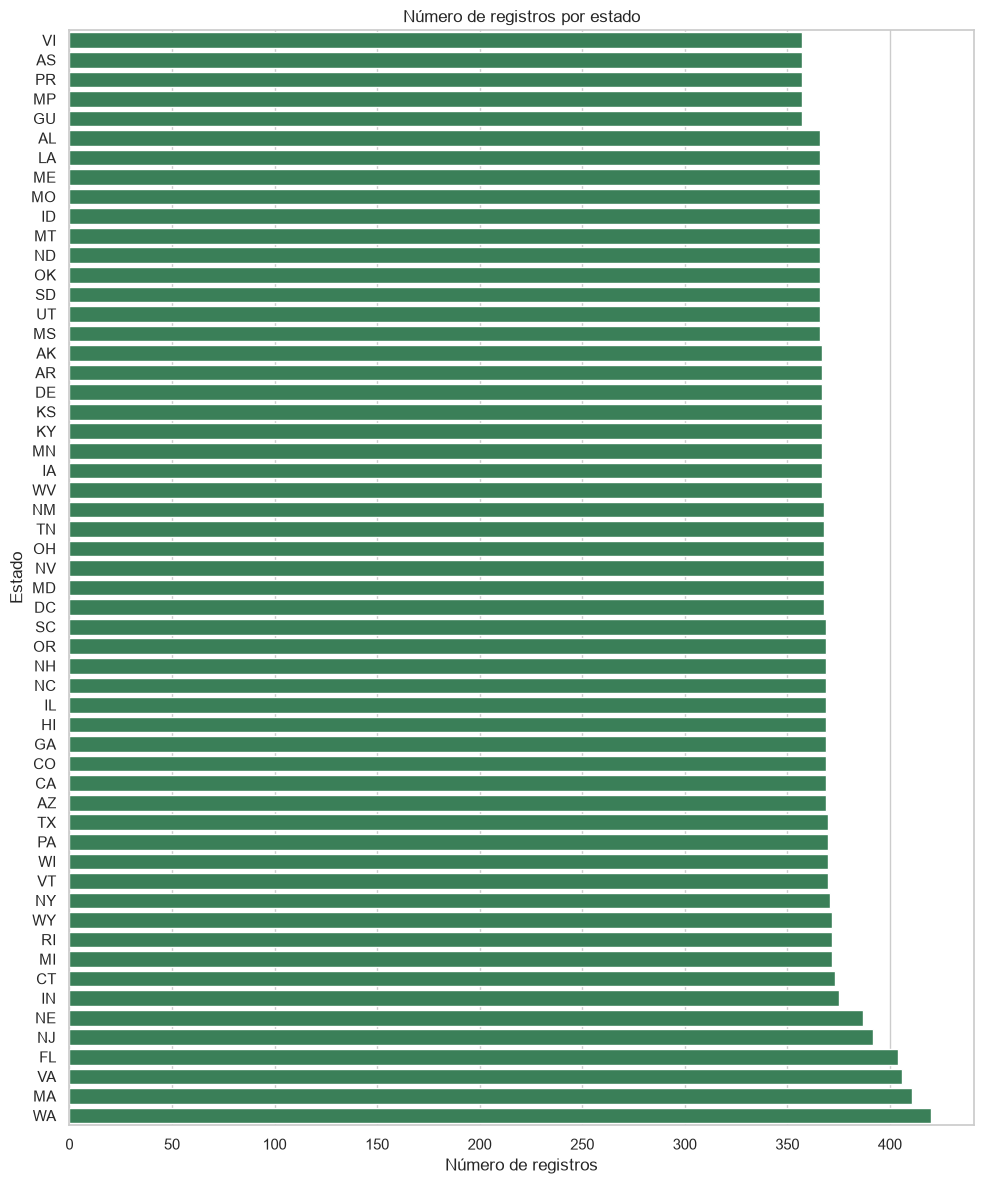

In [16]:
registros = df["estado"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(10, 12))
sns.barplot(
    x=registros.values,
    y=registros.index.astype(str),
    color="seagreen",
    ax=ax,
)
ax.set_title("Número de registros por estado")
ax.set_xlabel("Número de registros")
ax.set_ylabel("Estado")
plt.tight_layout()
plt.show()

Cada estado aporta entre **357 y 420 registros**, una cobertura parecida pero no idéntica. Las diferencias se deben a que algunos territorios empezaron a reportar más tarde o dejaron de hacerlo antes del final del periodo.

### 5.3. Distribución de los fallecimientos acumulados

El boxplot resume la mediana, la dispersión y los valores atípicos de los fallecimientos acumulados.

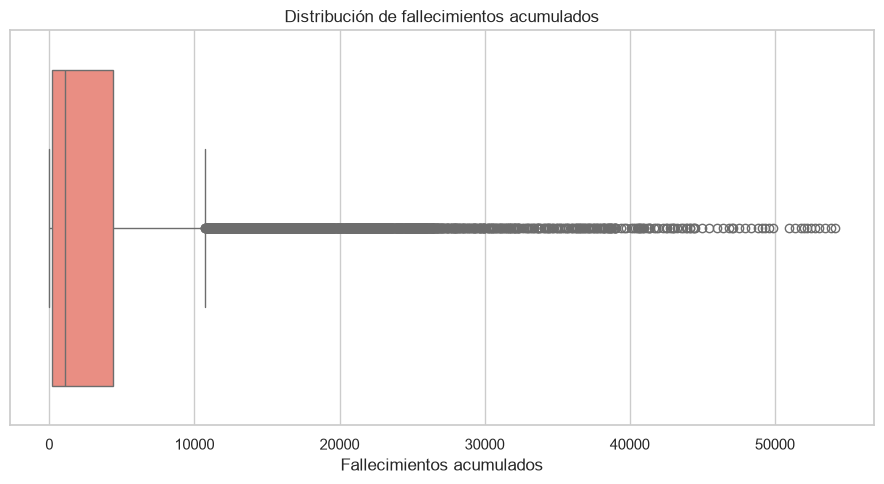

In [17]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(
    x=df["fallecimientos"].dropna(),
    color="salmon",
    ax=ax,
)
ax.set_title("Distribución de fallecimientos acumulados")
ax.set_xlabel("Fallecimientos acumulados")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

La caja se concentra en valores bajos y aparecen numerosos **valores atípicos** a la derecha. Son estados grandes con muchos fallecimientos acumulados; no los eliminamos porque son observaciones reales y relevantes, no errores de medición.

## 6. Análisis bivariado

Estudiamos tres relaciones: la evolución temporal de los casos, la relación entre pruebas y casos, y la comparación de casos entre estados.

### 6.1. Evolución temporal de los casos nuevos

Agregamos los casos nuevos de todos los estados por fecha para construir la serie diaria del país.

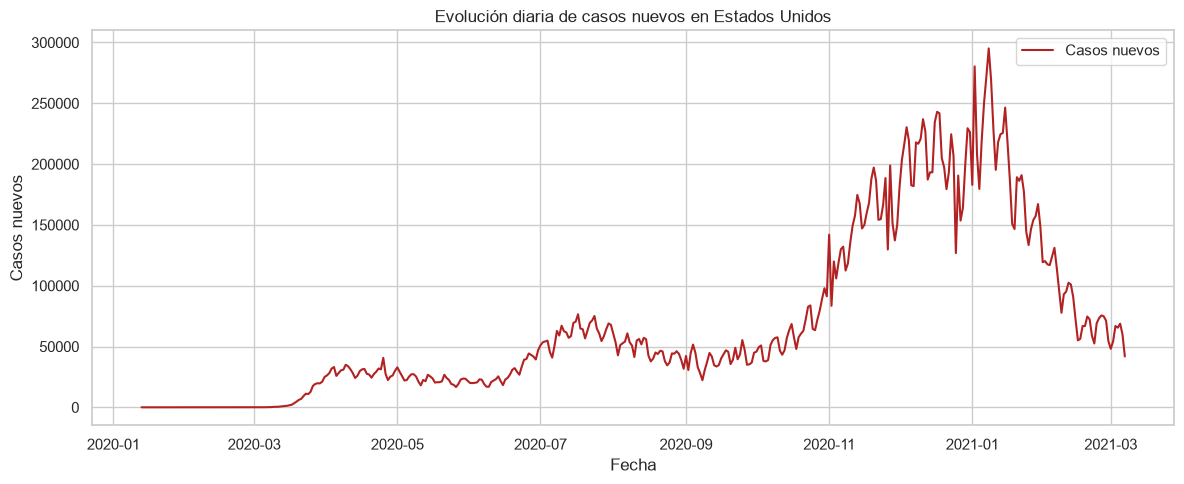

In [18]:
casos_por_dia = (
    df.groupby("fecha", as_index=False)["casos_nuevos"]
      .sum()
      .sort_values("fecha")
)

fig, ax = plt.subplots(figsize=(12, 5))
sns.lineplot(
    data=casos_por_dia,
    x="fecha",
    y="casos_nuevos",
    color="firebrick",
    label="Casos nuevos",
    ax=ax,
)
ax.set_title("Evolución diaria de casos nuevos en Estados Unidos")
ax.set_xlabel("Fecha")
ax.set_ylabel("Casos nuevos")
ax.legend()
plt.tight_layout()
plt.show()

La serie muestra **varias olas** de contagios. El máximo se alcanza el **8 de enero de 2021**, con **295.121 casos nuevos** en un solo día. Los picos negativos aislados corresponden a correcciones de reporte, no a descensos reales.

### 6.2. Pruebas totales frente a casos positivos

Para comparar estados sin mezclar días, usamos el último registro disponible de cada uno y representamos ambas variables en escala logarítmica, ya que abarcan varios órdenes de magnitud.

In [19]:
ultimo = (
    df.sort_values("fecha")
      .groupby("estado", observed=True)
      .tail(1)
      .copy()
)

ultimo[["estado", "casos_positivos", "fallecimientos", "pruebas_totales"]].head()

,estado,casos_positivos,fallecimientos,pruebas_totales
15906,PR,"101,632","2,062","407,604"
13337,NM,"186,922","3,808","2,783,542"
15179,OR,"157,079","2,296","3,850,973"
17751,TX,"2,686,818","44,451","19,907,384"
13705,NV,"296,190","5,037","2,770,192"


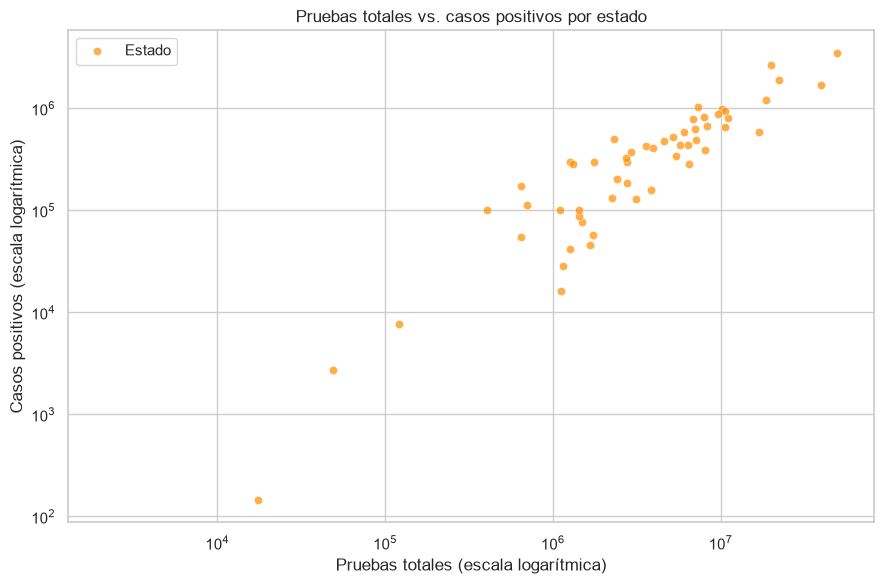

In [20]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(
    data=ultimo,
    x="pruebas_totales",
    y="casos_positivos",
    alpha=0.7,
    color="darkorange",
    label="Estado",
    ax=ax,
)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_title("Pruebas totales vs. casos positivos por estado")
ax.set_xlabel("Pruebas totales (escala logarítmica)")
ax.set_ylabel("Casos positivos (escala logarítmica)")
ax.legend()
plt.tight_layout()
plt.show()

In [21]:
ultimo[["pruebas_totales", "casos_positivos"]].corr().round(2)

,pruebas_totales,casos_positivos
pruebas_totales,1,0.90
casos_positivos,0.90,1


La nube de puntos sigue una tendencia creciente y la correlación de Pearson es **0,90**: los estados que realizaron más pruebas tienden a reportar más casos positivos. Es una asociación fuerte, pero **no implica causalidad**: ambos indicadores crecen con el tamaño de la población y con la intensidad de la epidemia.

### 6.3. Estados con más casos positivos

Comparamos los 10 estados con más casos acumulados en su último registro.

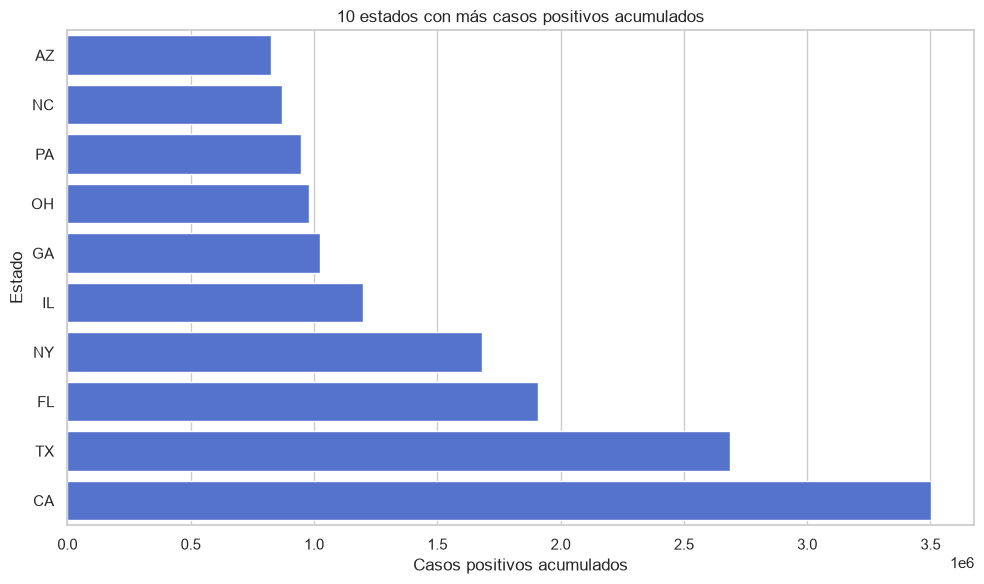

In [22]:
top10 = (
    ultimo.nlargest(10, "casos_positivos")
          .sort_values("casos_positivos")
          .assign(estado=lambda d: d["estado"].astype(str))
)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    data=top10,
    x="casos_positivos",
    y="estado",
    color="royalblue",
    ax=ax,
)
ax.set_title("10 estados con más casos positivos acumulados")
ax.set_xlabel("Casos positivos acumulados")
ax.set_ylabel("Estado")
plt.tight_layout()
plt.show()

**California** lidera con claridad, seguida de **Texas**, **Florida** y **Nueva York**. Son también algunos de los estados más poblados, lo que refuerza la necesidad de normalizar por población para comparar el impacto relativo (fuera del alcance de este nivel).

## 7. Nivel Medio: outliers, agregaciones y variables nuevas

En esta sección profundizamos en el dataset ya limpio: justificamos de forma explícita cada decisión de limpieza, detectamos valores atípicos, resumimos la información por estado y por mes, creamos variables nuevas, medimos correlaciones y analizamos tendencias temporales.


### 7.1. Justificación de las decisiones de limpieza

La sección 4 explicó cada decisión en detalle; esta tabla la resume para que el criterio sea fácil de revisar de un vistazo.


In [23]:
decisiones = pd.DataFrame(
    [
        (
            "Eliminar 46 columnas",
            "Metadatos (hash, fips), puntuaciones internas y columnas con más del 74 % de nulos",
            "Quedarnos con 10 variables relevantes y evitar ruido",
        ),
        (
            "Convertir fecha a datetime",
            "El entero AAAAMMDD no permite ordenar series temporales ni extraer mes o año",
            "Análisis temporal correcto",
        ),
        (
            "Convertir estado a categoría",
            "Tiene un número limitado de valores repetidos y se usa para agrupar",
            "Menor uso de memoria y agrupaciones más rápidas",
        ),
        (
            "Rellenar acumulados con ffill",
            "Un acumulado no puede disminuir; el último valor conocido es la mejor aproximación",
            "Se conservan las filas sin inventar datos",
        ),
        (
            "No imputar hospitalizados_actuales",
            "Es una medida instantánea, no un acumulado; rellenarla inventaría ingresos",
            "Se mantienen sus nulos y se excluyen en las medias",
        ),
        (
            "Mantener incrementos negativos",
            "Son correcciones retroactivas de los estados, no errores de medición",
            "Se preserva la serie original",
        ),
    ],
    columns=["Decisión", "Motivo", "Efecto"],
)
decisiones


,Decisión,Motivo,Efecto
0,Eliminar 46 columnas,"Metadatos (hash, fips), puntuaciones internas ...",Quedarnos con 10 variables relevantes y evitar...
1,Convertir fecha a datetime,El entero AAAAMMDD no permite ordenar series t...,Análisis temporal correcto
2,Convertir estado a categoría,Tiene un número limitado de valores repetidos ...,Menor uso de memoria y agrupaciones más rápidas
3,Rellenar acumulados con ffill,Un acumulado no puede disminuir; el último val...,Se conservan las filas sin inventar datos
4,No imputar hospitalizados_actuales,"Es una medida instantánea, no un acumulado; re...",Se mantienen sus nulos y se excluyen en las me...
5,Mantener incrementos negativos,"Son correcciones retroactivas de los estados, ...",Se preserva la serie original


La limpieza no elimina observaciones: se conservan las **20.780 filas**. Solo se descartan columnas poco informativas y se corrigen tipos y nulos de forma conservadora.


### 7.2. Detección de valores atípicos

Aplicamos la regla del rango intercuartílico (IQR): un valor es atípico si queda fuera de `[Q1 - 1,5·IQR, Q3 + 1,5·IQR]`. La aplicamos a los incrementos diarios, que son las variables donde un pico aislado puede distorsionar medias y gráficos.


In [24]:
def resumen_iqr(serie):
    serie = serie.dropna()
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr
    atipicos = ((serie < limite_inferior) | (serie > limite_superior)).sum()
    return pd.Series(
        {
            "Q1": q1,
            "Q3": q3,
            "IQR": iqr,
            "Límite inferior": limite_inferior,
            "Límite superior": limite_superior,
            "Atípicos": int(atipicos),
            "% atípicos": round(atipicos / len(serie) * 100, 1),
        }
    )


resumen_outliers = pd.DataFrame(
    {
        col: resumen_iqr(df[col])
        for col in ["casos_nuevos", "fallecimientos_nuevos", "pruebas_nuevas"]
    }
).T

resumen_outliers


,Q1,Q3,IQR,Límite inferior,Límite superior,Atípicos,% atípicos
casos_nuevos,65,"1,335.25","1,270.25","-1,840.38","3,240.62","2,390",11.50
fallecimientos_nuevos,0,24,24,-36,60,"2,208",10.60
pruebas_nuevas,"1,205.75","19,086.50","17,880.75","-25,615.38","45,907.62","2,033",9.80


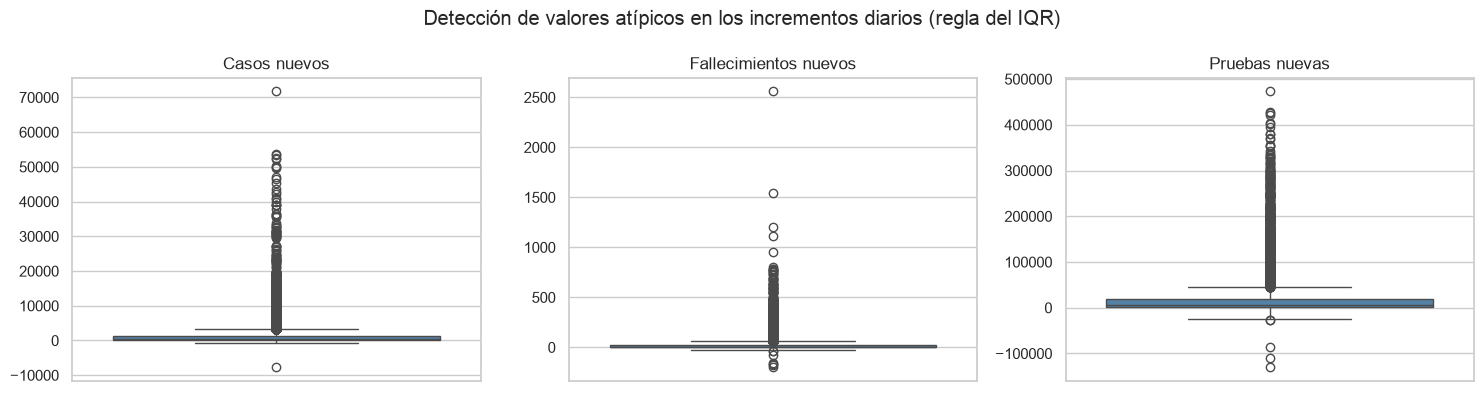

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, ["casos_nuevos", "fallecimientos_nuevos", "pruebas_nuevas"]):
    sns.boxplot(y=df[col], color="steelblue", ax=ax)
    ax.set_title(col.replace("_", " ").capitalize())
    ax.set_ylabel("")

plt.suptitle("Detección de valores atípicos en los incrementos diarios (regla del IQR)")
plt.tight_layout()
plt.show()


Los atípicos son frecuentes: **2.390 casos nuevos (11,5 %)**, **2.208 fallecimientos nuevos (10,6 %)** y **2.033 pruebas nuevas (9,8 %)** quedan fuera de los bigotes.

**Decisión:** no los eliminamos. Son picos reales de la epidemia, correcciones de reporte o estados muy grandes, no errores de medición; borrarlos ocultaría justamente los momentos de mayor impacto. Para resumir variables tan asimétricas usamos medianas y, cuando comparamos estados, ratios en lugar de totales. Los incrementos negativos no aparecen como atípicos porque el límite inferior del IQR ya es negativo.


### 7.3. Agrupación y resumen por estado

Agrupamos por estado con `groupby` y `agg` para obtener, en una sola tabla, los totales y las medias de cada territorio.


In [26]:
resumen_estado = (
    df.groupby("estado", observed=True)
    .agg(
        casos_totales=("casos_positivos", "max"),
        fallecimientos_totales=("fallecimientos", "max"),
        pruebas_totales=("pruebas_totales", "max"),
        casos_nuevos_medios=("casos_nuevos", "mean"),
        dias_reportados=("fecha", "nunique"),
    )
    .reset_index()
)

resumen_estado["tasa_letalidad"] = (
    resumen_estado["fallecimientos_totales"] / resumen_estado["casos_totales"]
)
resumen_estado["positividad"] = (
    resumen_estado["casos_totales"] / resumen_estado["pruebas_totales"]
)

resumen_estado.sort_values("casos_totales", ascending=False).head(10)


,estado,casos_totales,fallecimientos_totales,pruebas_totales,casos_nuevos_medios,dias_reportados,tasa_letalidad,positividad
5,CA,"3,501,394","54,124","49,646,014","9,488.73",369,0.02,0.07
47,TX,"2,686,818","44,451","19,907,384","7,261.67",370,0.02,0.13
10,FL,"1,909,209","32,266","22,339,182","4,725.76",404,0.02,0.09
37,NY,"1,681,169","39,029","39,695,100","4,531.45",371,0.02,0.04
16,IL,"1,198,335","23,014","18,640,190","3,247.51",369,0.02,0.06
11,GA,"1,023,487","17,906","7,359,069","2,773.67",369,0.02,0.14
38,OH,"978,471","17,656","10,257,157","2,658.89",368,0.02,0.10
41,PA,"948,643","24,349","10,681,716","2,563.90",370,0.03,0.09
30,NC,"872,176","11,502","9,688,838","2,363.62",369,0.01,0.09
4,AZ,"826,454","16,328","7,908,105","2,239.71",369,0.02,0.10


California, Texas, Florida y Nueva York lideran los casos acumulados. Al mirar los **ratios** aparecen otros protagonistas: la positividad más alta corresponde a **Idaho (26,8 %)**, **Puerto Rico (24,9 %)** y **Kansas (23,3 %)**, mientras que la tasa de letalidad más alta está en **Nueva Jersey (2,9 %)**, **Massachusetts (2,8 %)** y **Connecticut (2,7 %)**. Son indicadores descriptivos y dependen de la cantidad de pruebas y del criterio de reporte de cada estado.


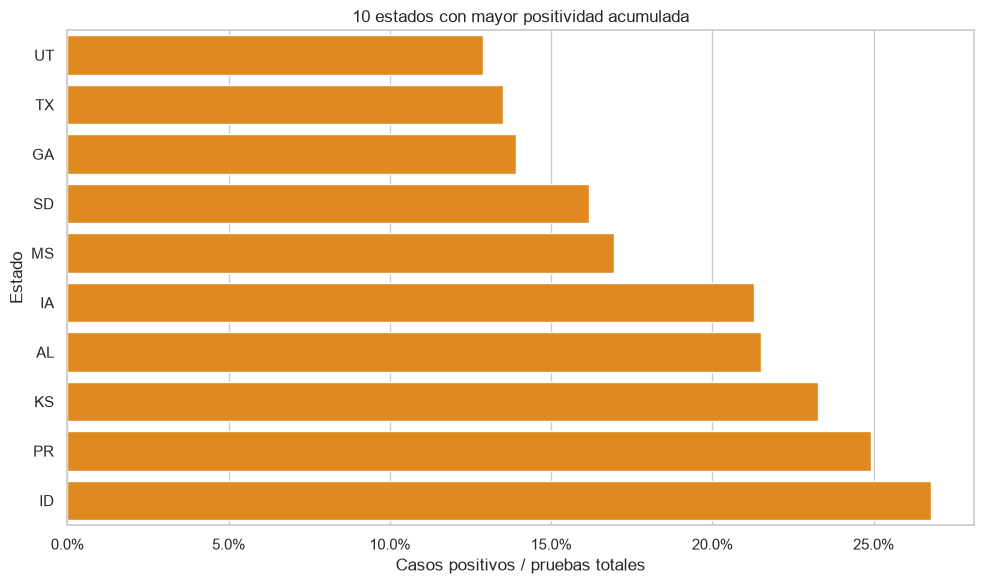

In [27]:
from matplotlib.ticker import PercentFormatter

top_positividad = (
    resumen_estado.nlargest(10, "positividad")
    .sort_values("positividad")
    .assign(estado=lambda d: d["estado"].astype(str))
)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    data=top_positividad,
    x="positividad",
    y="estado",
    color="darkorange",
    ax=ax,
)
ax.set_title("10 estados con mayor positividad acumulada")
ax.set_xlabel("Casos positivos / pruebas totales")
ax.set_ylabel("Estado")
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
plt.tight_layout()
plt.show()


### 7.4. Creación de variables nuevas

Creamos seis variables a partir de las existentes:

- `anio`, `mes` y `periodo`: partes de la fecha, para agregar por año y por mes.
- `ratio_positividad`: casos positivos divididos entre pruebas totales; mide qué proporción de las pruebas da positivo.
- `tasa_letalidad`: fallecimientos divididos entre casos positivos; aproxima la gravedad del brote.
- `rango_casos_nuevos`: agrupa los incrementos diarios en tramos para comparar la intensidad de los días.


In [28]:
df["anio"] = df["fecha"].dt.year
df["mes"] = df["fecha"].dt.month
df["periodo"] = df["fecha"].dt.to_period("M").astype(str)

df["ratio_positividad"] = (
    df["casos_positivos"] / df["pruebas_totales"].replace(0, np.nan)
)
df["tasa_letalidad"] = (
    df["fallecimientos"] / df["casos_positivos"].replace(0, np.nan)
)

df["rango_casos_nuevos"] = pd.cut(
    df["casos_nuevos"],
    bins=[-np.inf, -1, 0, 500, 2000, 5000, np.inf],
    labels=[
        "Corrección (negativo)",
        "Sin casos",
        "1-500",
        "501-2.000",
        "2.001-5.000",
        ">5.000",
    ],
)

df[
    [
        "fecha",
        "estado",
        "casos_nuevos",
        "anio",
        "mes",
        "ratio_positividad",
        "tasa_letalidad",
        "rango_casos_nuevos",
    ]
].head()


,fecha,estado,casos_nuevos,anio,mes,ratio_positividad,tasa_letalidad,rango_casos_nuevos
0,2020-03-06,AK,0,2020,3,NaN,NaN,Sin casos
1,2020-03-07,AK,0,2020,3,NaN,NaN,Sin casos
2,2020-03-08,AK,0,2020,3,NaN,NaN,Sin casos
3,2020-03-09,AK,0,2020,3,NaN,NaN,Sin casos
4,2020-03-10,AK,0,2020,3,NaN,NaN,Sin casos


In [29]:
df["rango_casos_nuevos"].value_counts().sort_index()


rango_casos_nuevos
Corrección (negativo)      24
Sin casos                1942
1-500                    9007
501-2.000                6046
2.001-5.000              2373
>5.000                   1388
Name: count, dtype: int64

Los ratios permiten comparar estados de tamaño muy distinto sin necesidad de una segunda fuente de población. El rango de casos nuevos muestra que la mayoría de los registros diarios se concentra por debajo de 2.000 casos, mientras que los días con más de 5.000 son poco frecuentes pero concentran buena parte del total.


### 7.5. Tabla dinámica: casos nuevos por estado y mes

Con `pivot_table` cruzamos los estados con mayor volumen acumulado y los meses del periodo para ver cómo se desplazó la epidemia entre territorios.


In [30]:
top_estados = resumen_estado.nlargest(8, "casos_totales")["estado"].tolist()

pivot_mensual = (
    df[df["estado"].isin(top_estados)]
    .pivot_table(
        index="periodo",
        columns="estado",
        values="casos_nuevos",
        aggfunc="sum",
    )
)

pivot_mensual.round(0)


estado,CA,FL,GA,IL,NY,OH,PA,TX
periodo,,,,,,,,
2020-01,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN
2020-02,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN
2020-03,"7,429","5,612","3,927","5,990","75,795","2,199","4,843","3,266"
2020-04,"41,435","26,917","22,226","46,924","228,577","15,828","40,920","24,821"
2020-05,"61,666","21,981","20,831","67,342","66,398","17,486","26,783","36,200"
2020-06,"118,149","95,379","34,305","23,978","22,684","16,276","14,060","95,699"
2020-07,"264,856","313,468","105,061","35,880","21,560","39,370","25,442","260,960"
2020-08,"210,497","153,272","84,119","56,607","19,742","31,998","21,977","192,023"
2020-09,"106,540","81,422","47,555","59,038","23,893","30,830","24,942","135,998"


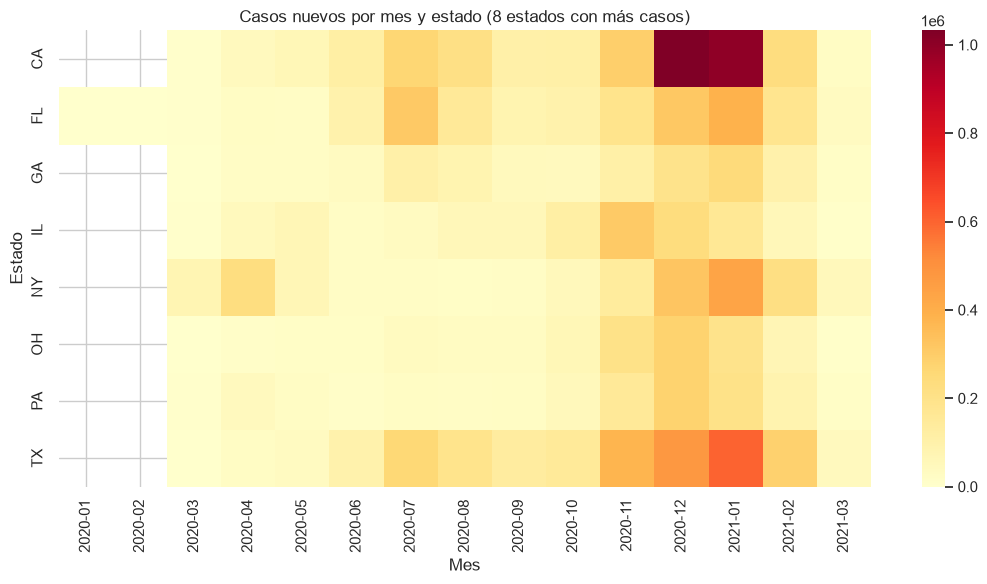

In [31]:
fig, ax = plt.subplots(figsize=(11, 6))
sns.heatmap(pivot_mensual.T, cmap="YlOrRd", ax=ax)
ax.set_title("Casos nuevos por mes y estado (8 estados con más casos)")
ax.set_xlabel("Mes")
ax.set_ylabel("Estado")
plt.tight_layout()
plt.show()


La tabla dinámica deja ver el relevo entre estados: Nueva York concentró una parte enorme de los casos en la primera ola de primavera de 2020, mientras que California, Texas y Florida ganaron peso en las olas de verano e invierno. El heatmap facilita detectar esos cambios de intensidad mes a mes.


### 7.6. Matriz de correlación

Calculamos la correlación de Pearson entre las variables numéricas usando **un único registro por estado** (el último disponible). Así evitamos que los 20.780 registros diarios repitan la misma información y inflen artificialmente las correlaciones.


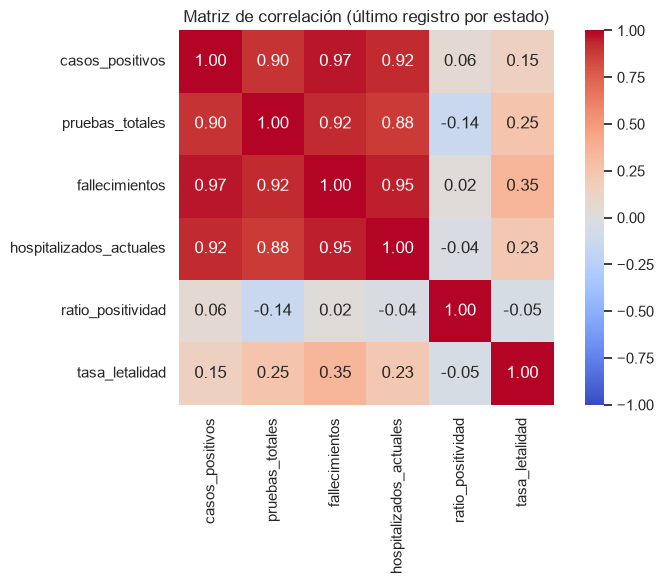

,casos_positivos,pruebas_totales,fallecimientos,hospitalizados_actuales,ratio_positividad,tasa_letalidad
casos_positivos,1,0.90,0.97,0.92,0.06,0.15
pruebas_totales,0.90,1,0.92,0.88,-0.14,0.25
fallecimientos,0.97,0.92,1,0.95,0.02,0.35
hospitalizados_actuales,0.92,0.88,0.95,1,-0.04,0.23
ratio_positividad,0.06,-0.14,0.02,-0.04,1,-0.05
tasa_letalidad,0.15,0.25,0.35,0.23,-0.05,1


In [32]:
ultimo = (
    df.sort_values("fecha")
    .groupby("estado", observed=True)
    .tail(1)
    .copy()
)

columnas_corr = [
    "casos_positivos",
    "pruebas_totales",
    "fallecimientos",
    "hospitalizados_actuales",
    "ratio_positividad",
    "tasa_letalidad",
]

correlaciones = ultimo[columnas_corr].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlaciones,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True,
)
plt.title("Matriz de correlación (último registro por estado)")
plt.tight_layout()
plt.show()

correlaciones.round(2)


Los acumulados están muy correlacionados entre sí: casos y pruebas (**0,90**), casos y fallecimientos (**0,97**) y fallecimientos y hospitalizados (**0,95**). Es esperable, porque todos crecen con el tamaño de la población y con el tiempo transcurrido.

Los ratios rompen ese patrón: la positividad apenas correlaciona con los casos (**0,06**) y la tasa de letalidad muestra una relación débil con los fallecimientos (**0,35**). Esto indica que el tamaño del estado explica los totales, pero no la intensidad ni la gravedad relativa. Ninguna de estas correlaciones demuestra causalidad.


### 7.7. Tendencias temporales

Para suavizar los picos y las correcciones de reporte calculamos una **media móvil de 7 días** sobre la serie nacional de casos y fallecimientos nuevos. Después agregamos por mes para comparar la magnitud de cada ola.


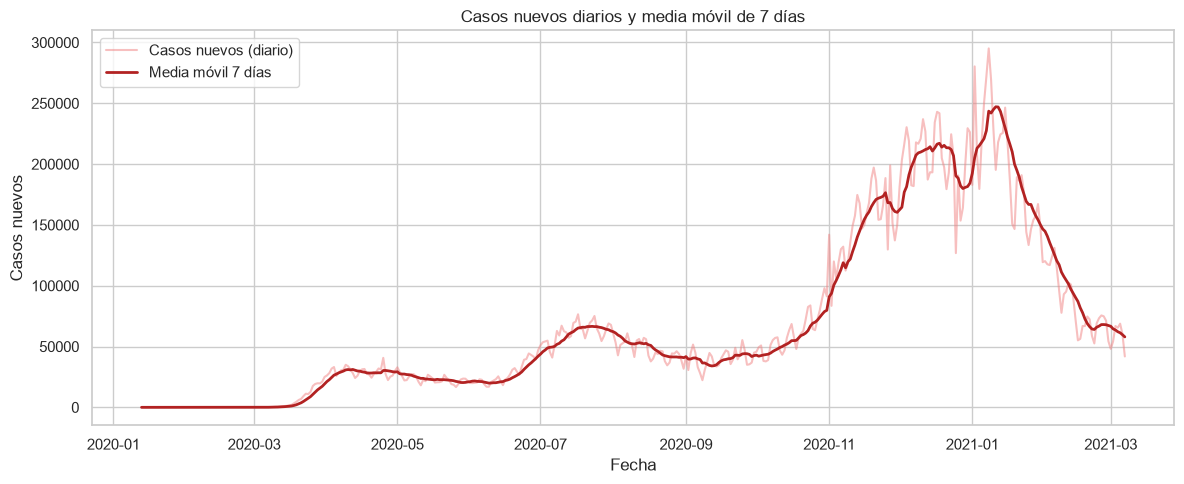

In [33]:
diario = (
    df.groupby("fecha", as_index=False)
    .agg(
        casos_nuevos=("casos_nuevos", "sum"),
        fallecimientos_nuevos=("fallecimientos_nuevos", "sum"),
    )
    .sort_values("fecha")
)

diario["casos_media_7d"] = diario["casos_nuevos"].rolling(7, min_periods=1).mean()
diario["fallecimientos_media_7d"] = (
    diario["fallecimientos_nuevos"].rolling(7, min_periods=1).mean()
)

fig, ax = plt.subplots(figsize=(12, 5))
sns.lineplot(
    data=diario,
    x="fecha",
    y="casos_nuevos",
    color="lightcoral",
    alpha=0.5,
    label="Casos nuevos (diario)",
    ax=ax,
)
sns.lineplot(
    data=diario,
    x="fecha",
    y="casos_media_7d",
    color="firebrick",
    linewidth=2,
    label="Media móvil 7 días",
    ax=ax,
)
ax.set_title("Casos nuevos diarios y media móvil de 7 días")
ax.set_xlabel("Fecha")
ax.set_ylabel("Casos nuevos")
ax.legend()
plt.tight_layout()
plt.show()


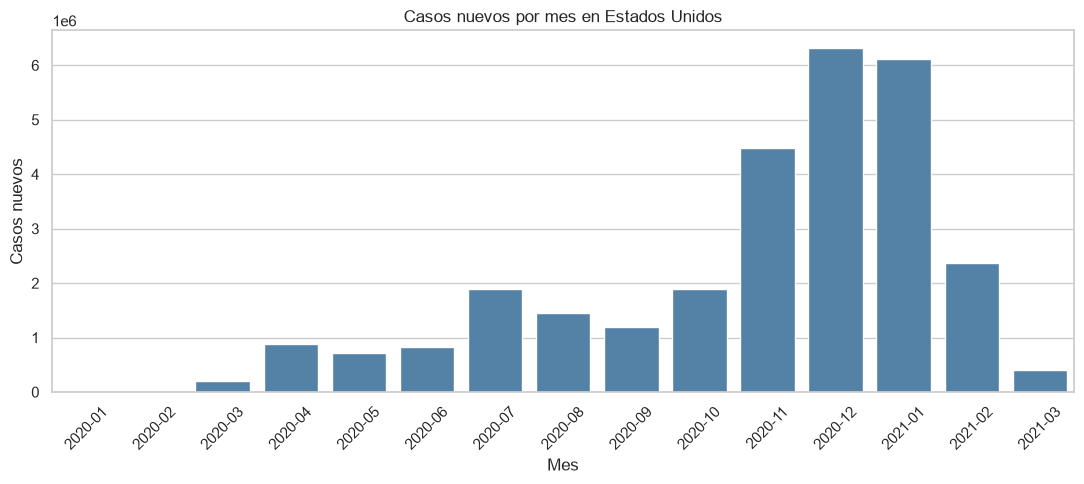

,periodo,casos_nuevos,fallecimientos_nuevos
9,2020-10,1892015,23545
10,2020-11,4475991,37065
11,2020-12,6323266,77112
12,2021-01,6112572,95387
13,2021-02,2374243,71058
14,2021-03,405300,11904


In [34]:
mensual = (
    df.groupby("periodo", as_index=False)
    .agg(
        casos_nuevos=("casos_nuevos", "sum"),
        fallecimientos_nuevos=("fallecimientos_nuevos", "sum"),
    )
    .sort_values("periodo")
)

fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(
    data=mensual,
    x="periodo",
    y="casos_nuevos",
    color="steelblue",
    ax=ax,
)
ax.set_title("Casos nuevos por mes en Estados Unidos")
ax.set_xlabel("Mes")
ax.set_ylabel("Casos nuevos")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

mensual.tail(6)


La media móvil muestra tres grandes olas: primavera de 2020, verano de 2020 e invierno de 2020-2021. Diciembre de 2020 fue el mes con más casos nuevos (**6,32 millones**) y enero de 2021 el de más fallecimientos (**95.387**). La tendencia mensual confirma que el pico diario del 8 de enero de 2021 no fue un caso aislado, sino el final de una ola sostenida.


## 8. Respuestas a las preguntas y conclusiones

### 8.1. ¿Cómo evolucionaron los casos y los fallecimientos?

La pandemia evolucionó en **varias olas**. Los casos nuevos alcanzaron su máximo diario el **8 de enero de 2021** (295.121 en un día) y los fallecimientos el **12 de febrero de 2021** (5.427). Agregando por mes, diciembre de 2020 fue el mes con más casos (6,32 millones) y enero de 2021 el de más fallecimientos (95.387). Al final del periodo, los últimos registros por estado suman aproximadamente **28,8 millones de casos** y **515.000 fallecimientos**.

### 8.2. ¿Qué estados concentraron más casos positivos?

California (≈3,5 M), Texas (≈2,7 M), Florida (≈1,9 M) y Nueva York (≈1,7 M) encabezan el ranking. La concentración refleja en parte el tamaño de su población, por lo que no debe interpretarse como un mayor impacto relativo. Al normalizar con ratios, la positividad más alta aparece en Idaho, Puerto Rico y Kansas, y la tasa de letalidad más alta en Nueva Jersey, Massachusetts y Connecticut.

### 8.3. ¿Existe relación entre pruebas realizadas y casos positivos?

Sí. La correlación entre pruebas totales y casos positivos por estado es **0,90**, una asociación lineal positiva fuerte. No obstante, la relación no es causal: más pruebas permiten detectar más casos, pero también los estados más poblados y con más transmisión realizan más pruebas. Los ratios de positividad y letalidad apenas correlacionan con los totales, lo que confirma que el tamaño del estado explica los acumulados pero no la intensidad relativa.

### 8.4. ¿Qué aportó el análisis del Nivel Medio?

- La regla del IQR detectó atípicos en torno al **10-11 %** de los incrementos diarios; decidimos conservarlos por ser picos reales o correcciones, no errores.
- El `groupby` y la `pivot_table` mostraron el relevo entre estados a lo largo de las olas.
- Las seis variables nuevas permiten comparar positividad, letalidad e intensidad diaria sin depender solo de totales.
- La matriz de correlación separa el efecto del tamaño (acumulados) del efecto de la intensidad relativa (ratios).
- La media móvil y la agregación mensual confirman tres olas y sitúan el pico mensual en diciembre de 2020.

## 9. Conclusiones

- El análisis confirma que la COVID-19 afectó de forma **desigual** a los estados: unos pocos concentran la mayor parte de los casos y fallecimientos.
- La evolución temporal muestra **oleadas claras**, con un pico de casos a principios de 2021 y un pico de fallecimientos unas semanas después.
- Existe una **relación positiva fuerte entre pruebas y casos**, coherente con la dinámica de detección de la enfermedad.
- La limpieza fue necesaria: el dataset original tiene muchas columnas casi vacías, fechas como enteros y correcciones negativas en los incrementos.
- Los **ratios** (positividad y letalidad) aportan una lectura más justa que los totales, aunque siguen condicionados por las diferencias de reporte entre estados.

### Limitaciones

- Los datos son **acumulados y absolutos**; no se normalizan por población, por lo que los estados grandes aparecen sobrerrepresentados.
- Hay **diferencias de criterio y de calidad de reporte** entre estados, y correcciones retroactivas que generan valores negativos.
- El periodo termina en **marzo de 2021**, antes de la vacunación masiva, así que las conclusiones no describen etapas posteriores.
- Los ratios calculados con datos acumulados son aproximaciones descriptivas; no sustituyen un análisis epidemiológico con denominadores de población.
